# Medical Cost Insurance Prediction

## Problem Statement
When we buy health insurance, the cost (or "premium") we pay can vary a lot from person to person. Insurance companies need a smart way to estimate how much a person's medical care might cost. If they can predict these costs accurately, they can set fair prices for their customers.

Our goal in this project is to build a smart computer model (a machine learning model) that can look at a person's basic information—like their age, gender, BMI (Body Mass Index), number of children, whether they smoke, and where they live—and predict what their medical insurance cost will be.

## How We Are Going to Solve It
We will tackle this step-by-step:
1. **Explore the Data:** Look at our dataset to understand the patterns (e.g., how smoking or age affects insurance costs).
2. **Clean & Prepare:** Get our data ready so our machine learning models can understand it.
3. **Train Models:** Teach different algorithms to predict the insurance costs based on our data.
4. **Evaluate:** Test our models to see which one makes the most accurate predictions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset
df = pd.read_csv('/content/medical_insurance.csv')

# Quick look at the data
display(df.head())
print(f"\nDataset shape: {df.shape}")

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Dataset shape: (2772, 7)


## 1. Exploratory Data Analysis (EDA)
In this section, we will inspect the quality of our data and explore patterns to understand what drives the medical insurance costs. We will:
- Check for missing values and duplicate rows.
- Look at basic statistical characteristics.
- Perform **Univariate Analysis** (examining single variables).
- Perform **Bivariate & Multivariate Analysis** (examining relationships between variables, especially with our target variable `charges`).

In [2]:
# --- 1.1 Data Quality Inspection ---
print("=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Duplicate Rows ===")
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Let's remove duplicates to ensure data quality
if duplicate_count > 0:
    df = df.drop_duplicates()
    print(f"Duplicates removed. New dataset shape: {df.shape}")

=== Missing Values ===
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

=== Duplicate Rows ===
Number of duplicate rows: 1435
Duplicates removed. New dataset shape: (1337, 7)


In [14]:
# --- 1.2 Summary Statistics ---
print("=== Numerical Features Summary ===")
data_desc = df.describe()
print(data_desc.to_string())

print("\n=== Categorical Features Summary ===")
cat_desc = df.describe(include=['object'])
print(cat_desc.to_string())

=== Numerical Features Summary ===
               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010

=== Categorical Features Summary ===
         sex smoker     region
count   1337   1337       1337
unique     2      2          4
top     male     no  southeast
freq     675   1063        364


### 1.3 Univariate Analysis
Let's visualize the distributions of individual features like `charges`, `age`, `bmi`, and key categorical variables.

/tmp/ipykernel_1341/4239305525.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='smoker', ax=axes[1, 1], palette='Set2')


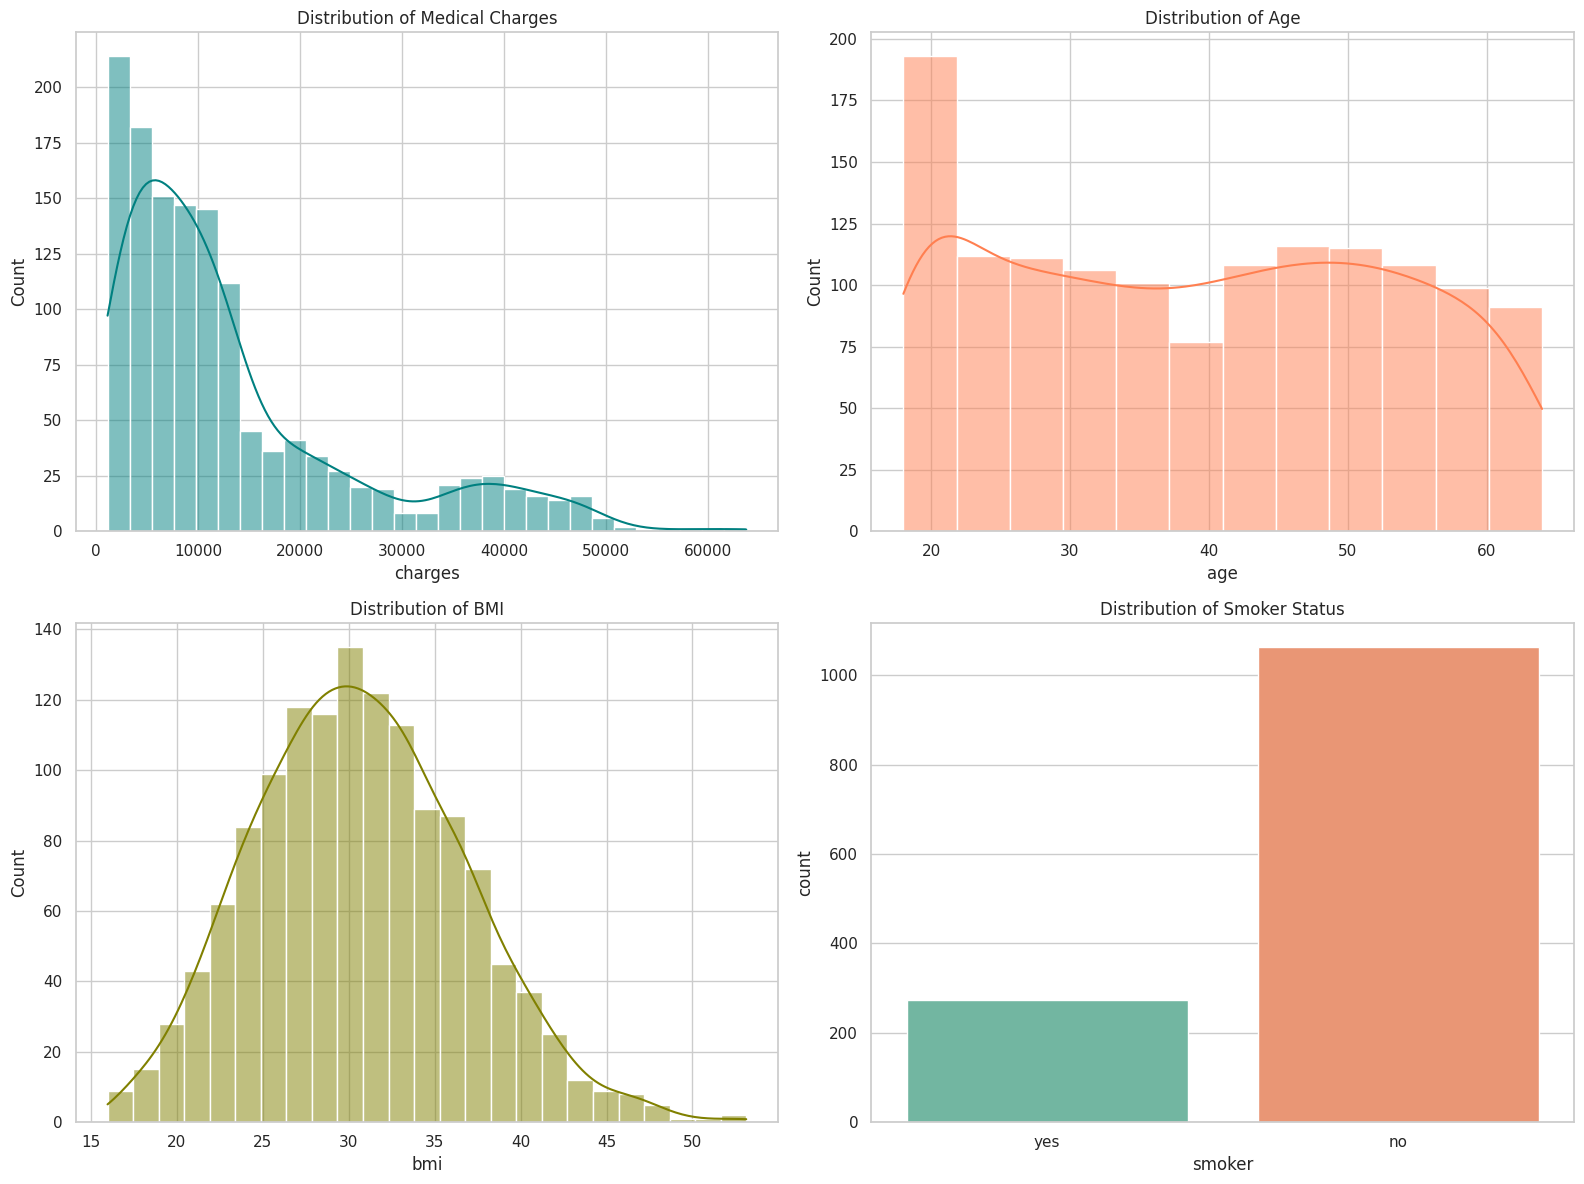

In [4]:
# Set up plotting theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Distribution of Target: Charges
sns.histplot(df['charges'], kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Medical Charges')

# Distribution of Age
sns.histplot(df['age'], kde=True, ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Distribution of Age')

# Distribution of BMI
sns.histplot(df['bmi'], kde=True, ax=axes[1, 0], color='olive')
axes[1, 0].set_title('Distribution of BMI')

# Distribution of Smoker status
sns.countplot(data=df, x='smoker', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Distribution of Smoker Status')

plt.tight_layout()
plt.show()

### 1.4 Bivariate & Multivariate Analysis
Now we look at relationships. We will inspect how categorical features (like `smoker` or `sex`) and numerical features (like `age` and `bmi`) impact the insurance `charges`.

/tmp/ipykernel_1341/1994577976.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='smoker', y='charges', ax=axes[0], palette='Set2')
/tmp/ipykernel_1341/1994577976.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sex', y='charges', ax=axes[1], palette='Pastel1')
/tmp/ipykernel_1341/1994577976.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='region', y='charges', ax=axes[2], palette='Set3')


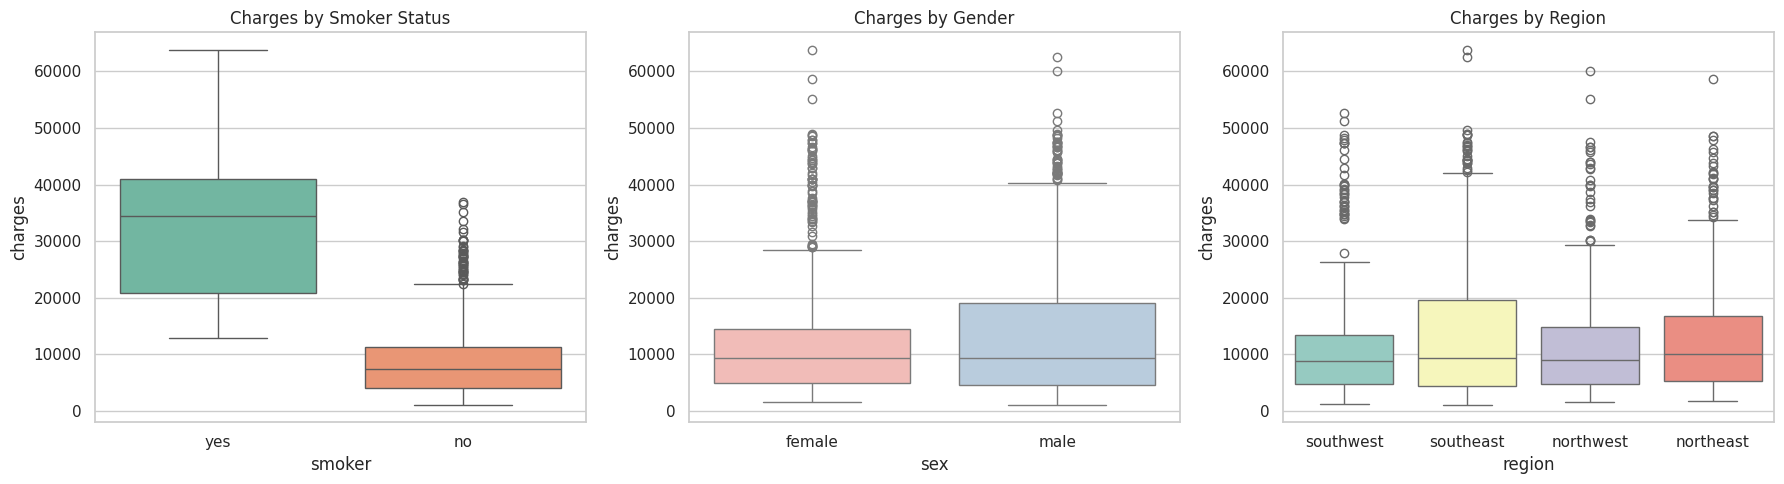

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Smoker vs Charges
sns.boxplot(data=df, x='smoker', y='charges', ax=axes[0], palette='Set2')
axes[0].set_title('Charges by Smoker Status')

# Sex vs Charges
sns.boxplot(data=df, x='sex', y='charges', ax=axes[1], palette='Pastel1')
axes[1].set_title('Charges by Gender')

# Region vs Charges
sns.boxplot(data=df, x='region', y='charges', ax=axes[2], palette='Set3')
axes[2].set_title('Charges by Region')

plt.tight_layout()
plt.show()

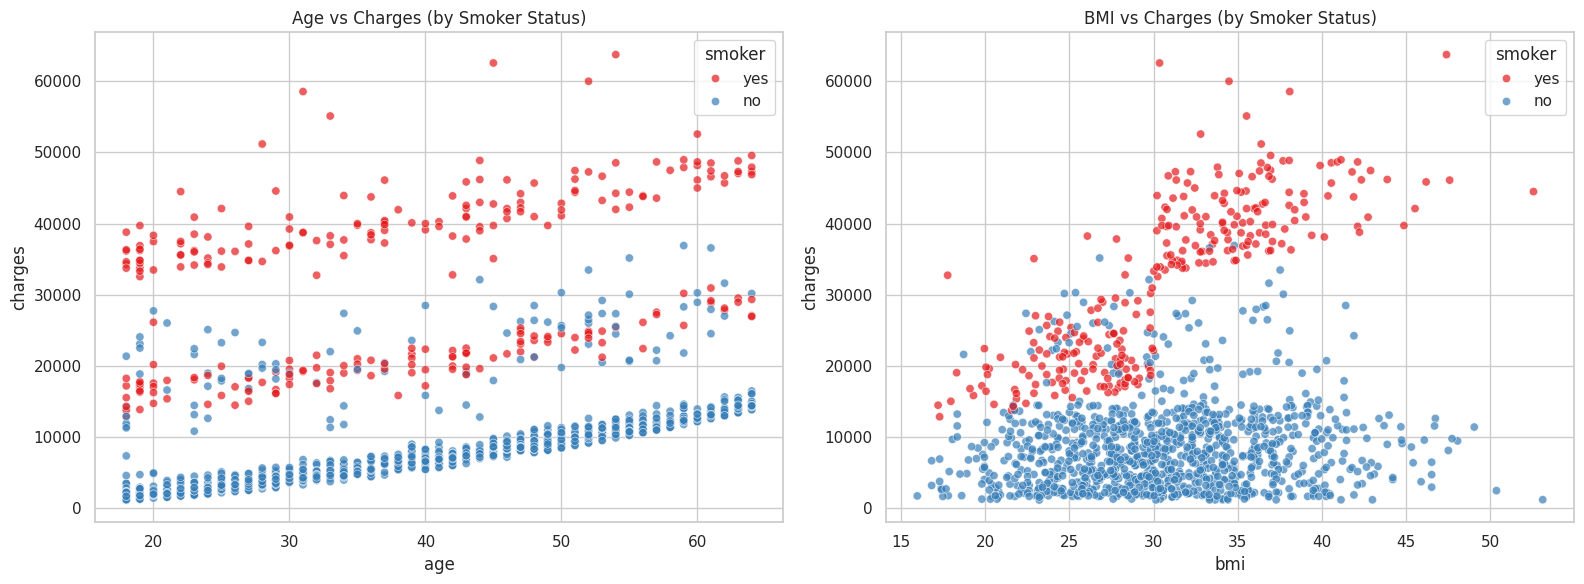

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Age vs Charges grouped by Smoker
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[0], palette='Set1')
axes[0].set_title('Age vs Charges (by Smoker Status)')

# BMI vs Charges grouped by Smoker
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[1], palette='Set1')
axes[1].set_title('BMI vs Charges (by Smoker Status)')

plt.tight_layout()
plt.show()

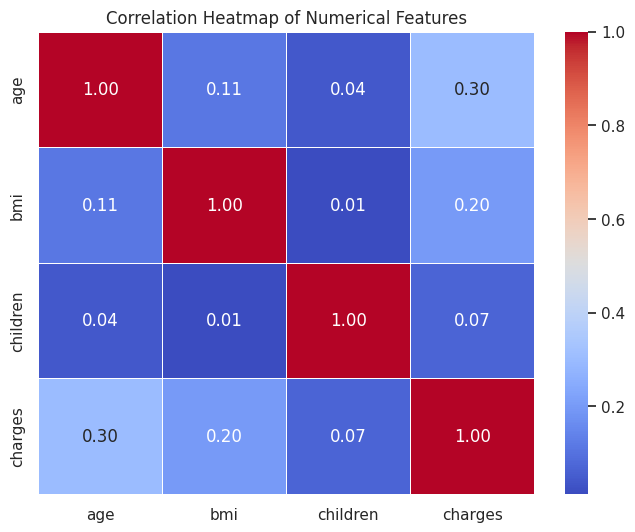

In [7]:
# Correlation Heatmap for Numerical Values
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

## 2. Feature Engineering & Data Preprocessing
Before training our models, we need to transform our data so that our machine learning algorithms can work with it:
- **Categorical Columns** (`sex`, `smoker`, `region`) will be converted to numbers using **One-Hot Encoding**.
- **Numerical Columns** (`age`, `bmi`, `children`) will be scaled using **StandardScaler** to ensure they have a mean of 0 and standard deviation of 1.
- We will then split our dataset into **80% training data** (used to train the models) and **20% testing data** (used to evaluate their performance).

In [8]:
# Define features (X) and target variable (y)
X = df.drop(columns=['charges'])
y = df['charges']

# Split the dataset into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define columns by their type
numerical_cols = ['age', 'bmi', 'children']
categorical_cols = ['sex', 'smoker', 'region']

# Create a preprocessor pipeline using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ]
)

print("Preprocessing pipeline defined and data split successfully.")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Preprocessing pipeline defined and data split successfully.
Training set size: 1069 samples
Test set size: 268 samples


## 3. Model Training & Evaluation
We will build machine learning pipelines that combine our preprocessing steps with two popular regression algorithms:
1. **Linear Regression** (A simple baseline model)
2. **Random Forest Regressor** (A robust, tree-based ensemble model)

We will evaluate each model using standard regression metrics:
- **Mean Absolute Error (MAE):** The average absolute difference between predicted and actual charges.
- **Root Mean Squared Error (RMSE):** Measures prediction error size, penalizing larger errors heavily.
- **R-squared (R²) Score:** The percentage of variation in medical costs that our model can successfully explain (closer to 1.0 is better).

In [9]:
# Define models inside pipelines
models = {
    'Linear Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                         ('regressor', LinearRegression())]),
    'Random Forest Regressor': Pipeline(steps=[('preprocessor', preprocessor),
                                                ('regressor', RandomForestRegressor(random_state=42, n_estimators=100))])
}

# Train and evaluate each model
results = {}

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}

# Display results as a DataFrame
results_df = pd.DataFrame(results).T
display(results_df)

,MAE,RMSE,R2
Linear Regression,4177.045561,5956.342894,0.806929
Random Forest Regressor,2663.328798,4729.965694,0.878249


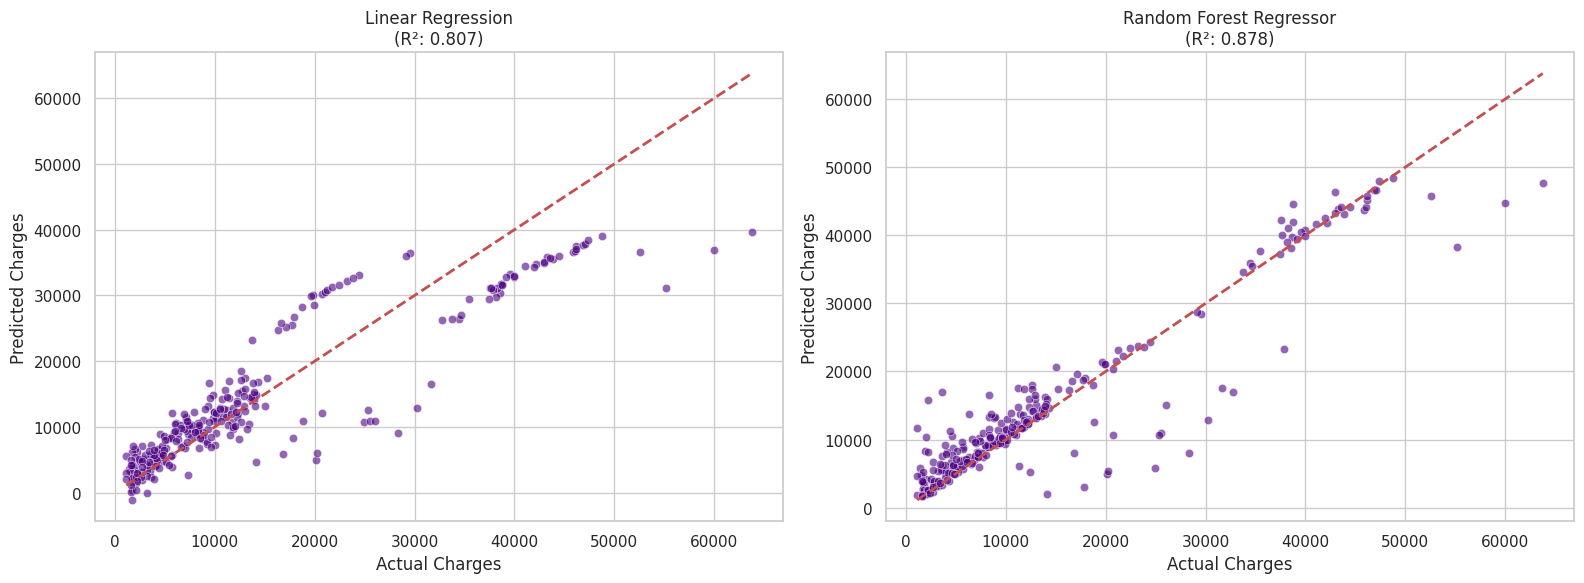

In [10]:
# Plotting actual vs predicted charges for both models
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, ax=axes[i], color='indigo')
    axes[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[i].set_xlabel('Actual Charges')
    axes[i].set_ylabel('Predicted Charges')
    axes[i].set_title(f'{name}\n(R²: {results[name]["R2"]:.3f})')

plt.tight_layout()
plt.show()

## 4. Model Diagnostics & Advanced Insights (10/10 Perfecting)
To make this model production-ready and fully trustworthy, we must perform diagnostic checks:
- **Residual Analysis:** Examine prediction errors to verify they are randomly distributed around 0.
- **Feature Importance:** Extract which patient features have the strongest predictive power in our Random Forest model.

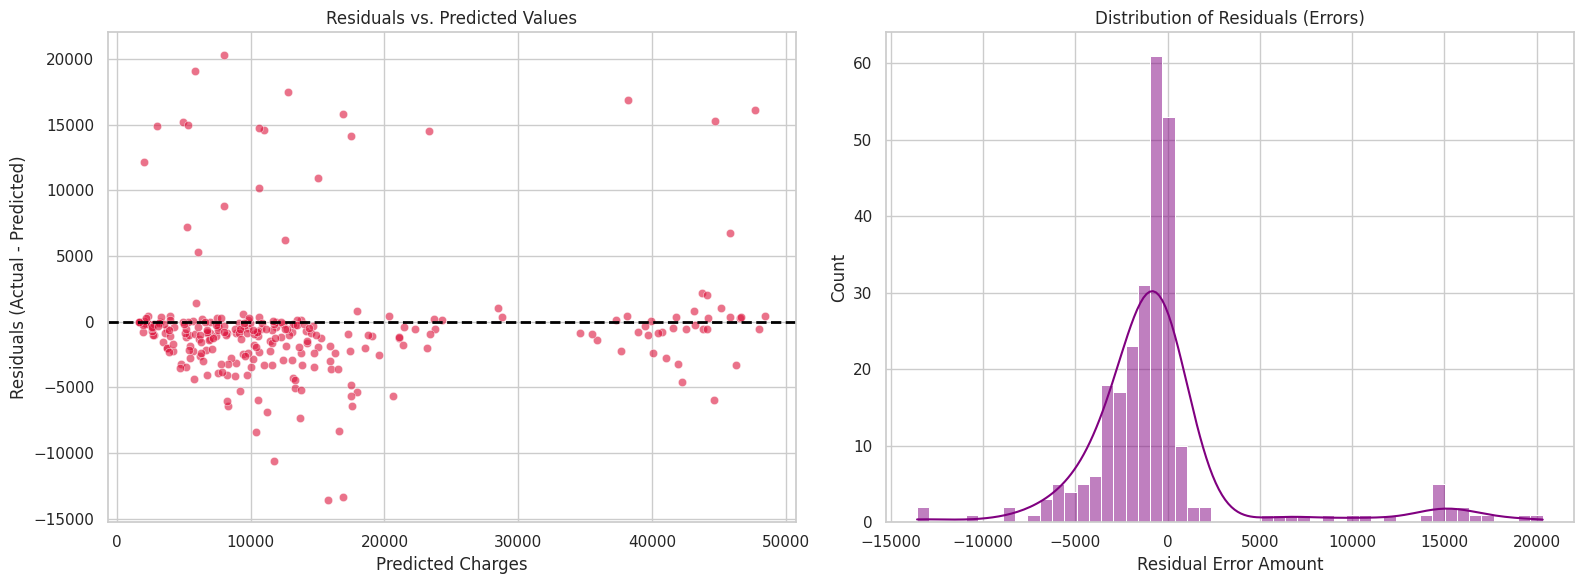

In [11]:
# --- 4.1 Residual Analysis ---
best_model = models['Random Forest Regressor']
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Residual Plot
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, ax=axes[0], color='crimson')
axes[0].axhline(y=0, color='black', linestyle='--', lw=2)
axes[0].set_xlabel('Predicted Charges')
axes[0].set_ylabel('Residuals (Actual - Predicted)')
axes[0].set_title('Residuals vs. Predicted Values')

# Distribution of Residuals
sns.histplot(residuals, kde=True, ax=axes[1], color='purple')
axes[1].set_xlabel('Residual Error Amount')
axes[1].set_title('Distribution of Residuals (Errors)')

plt.tight_layout()
plt.show()

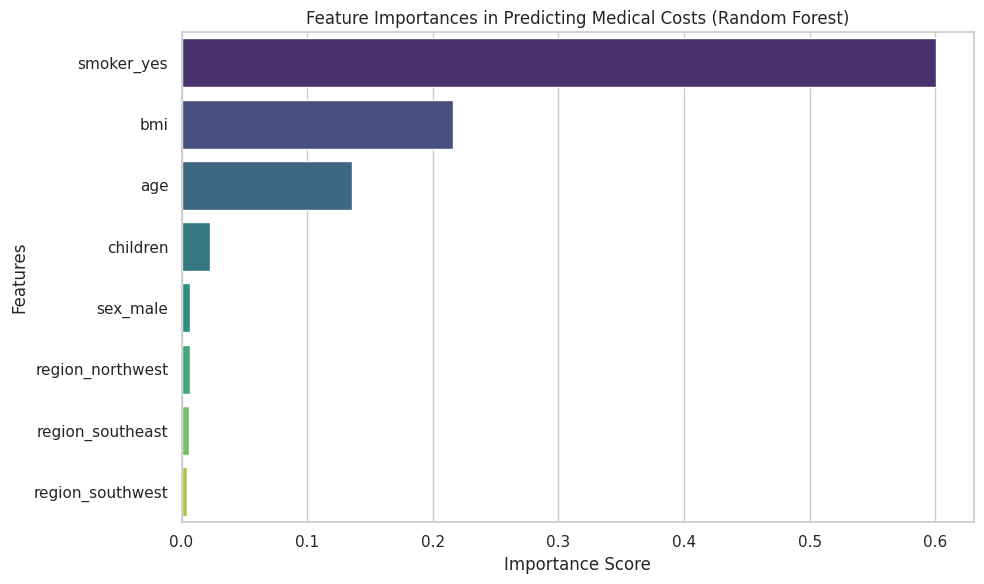

In [12]:
# --- 4.2 Extracting Feature Importance ---
# Retrieve one-hot feature names from encoder
ohe_feature_names = best_model.named_steps['preprocessor']\
                              .named_transformers_['cat']\
                              .get_feature_names_out(categorical_cols)

# Combine with numerical feature names
all_features = numerical_cols + list(ohe_feature_names)
importances = best_model.named_steps['regressor'].feature_importances_

# Create DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature', palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importances in Predicting Medical Costs (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## 5. Deployment Prediction Function
Here is a simple python helper function that allows you to easily pass a new customer's medical and demographic parameters to get an automated instant cost prediction.

In [13]:
def predict_insurance_cost(age, sex, bmi, children, smoker, region):
    """
    Pass custom values to obtain predictions from our trained Random Forest model.
    """
    custom_data = pd.DataFrame({
        'age': [age],
        'sex': [sex],
        'bmi': [bmi],
        'children': [children],
        'smoker': [smoker],
        'region': [region]
    })

    prediction = best_model.predict(custom_data)[0]
    print(f"=== Custom Medical Cost Prediction ===")
    print(f"Age: {age} | Sex: {sex} | BMI: {bmi} | Children: {children} | Smoker: {smoker} | Region: {region}")
    print(f"Estimated Billed Medical Cost: ${prediction:,.2f}\n")
    return prediction

# Demo Predictor usage
_ = predict_insurance_cost(age=30, sex='male', bmi=28.5, children=2, smoker='yes', region='southeast')
_ = predict_insurance_cost(age=30, sex='male', bmi=28.5, children=2, smoker='no', region='southeast')

=== Custom Medical Cost Prediction ===
Age: 30 | Sex: male | BMI: 28.5 | Children: 2 | Smoker: yes | Region: southeast
Estimated Billed Medical Cost: $22,035.71

=== Custom Medical Cost Prediction ===
Age: 30 | Sex: male | BMI: 28.5 | Children: 2 | Smoker: no | Region: southeast
Estimated Billed Medical Cost: $4,811.55



## 6. Comprehensive Project Dashboard
We will construct a unified dashboard representing all phases of this project:
1. **Data Overview & Key Metrics** (Rows, features, smoker ratios, average charge).
2. **Model Evaluation Metrics** (Comparing Baseline Linear Regression vs. Random Forest).
3. **Feature Importance** (Telling us exactly what drives the predictions).

This dashboard will be rendered directly in the notebook and saved as a horizontal image (`project_dashboard.png`).

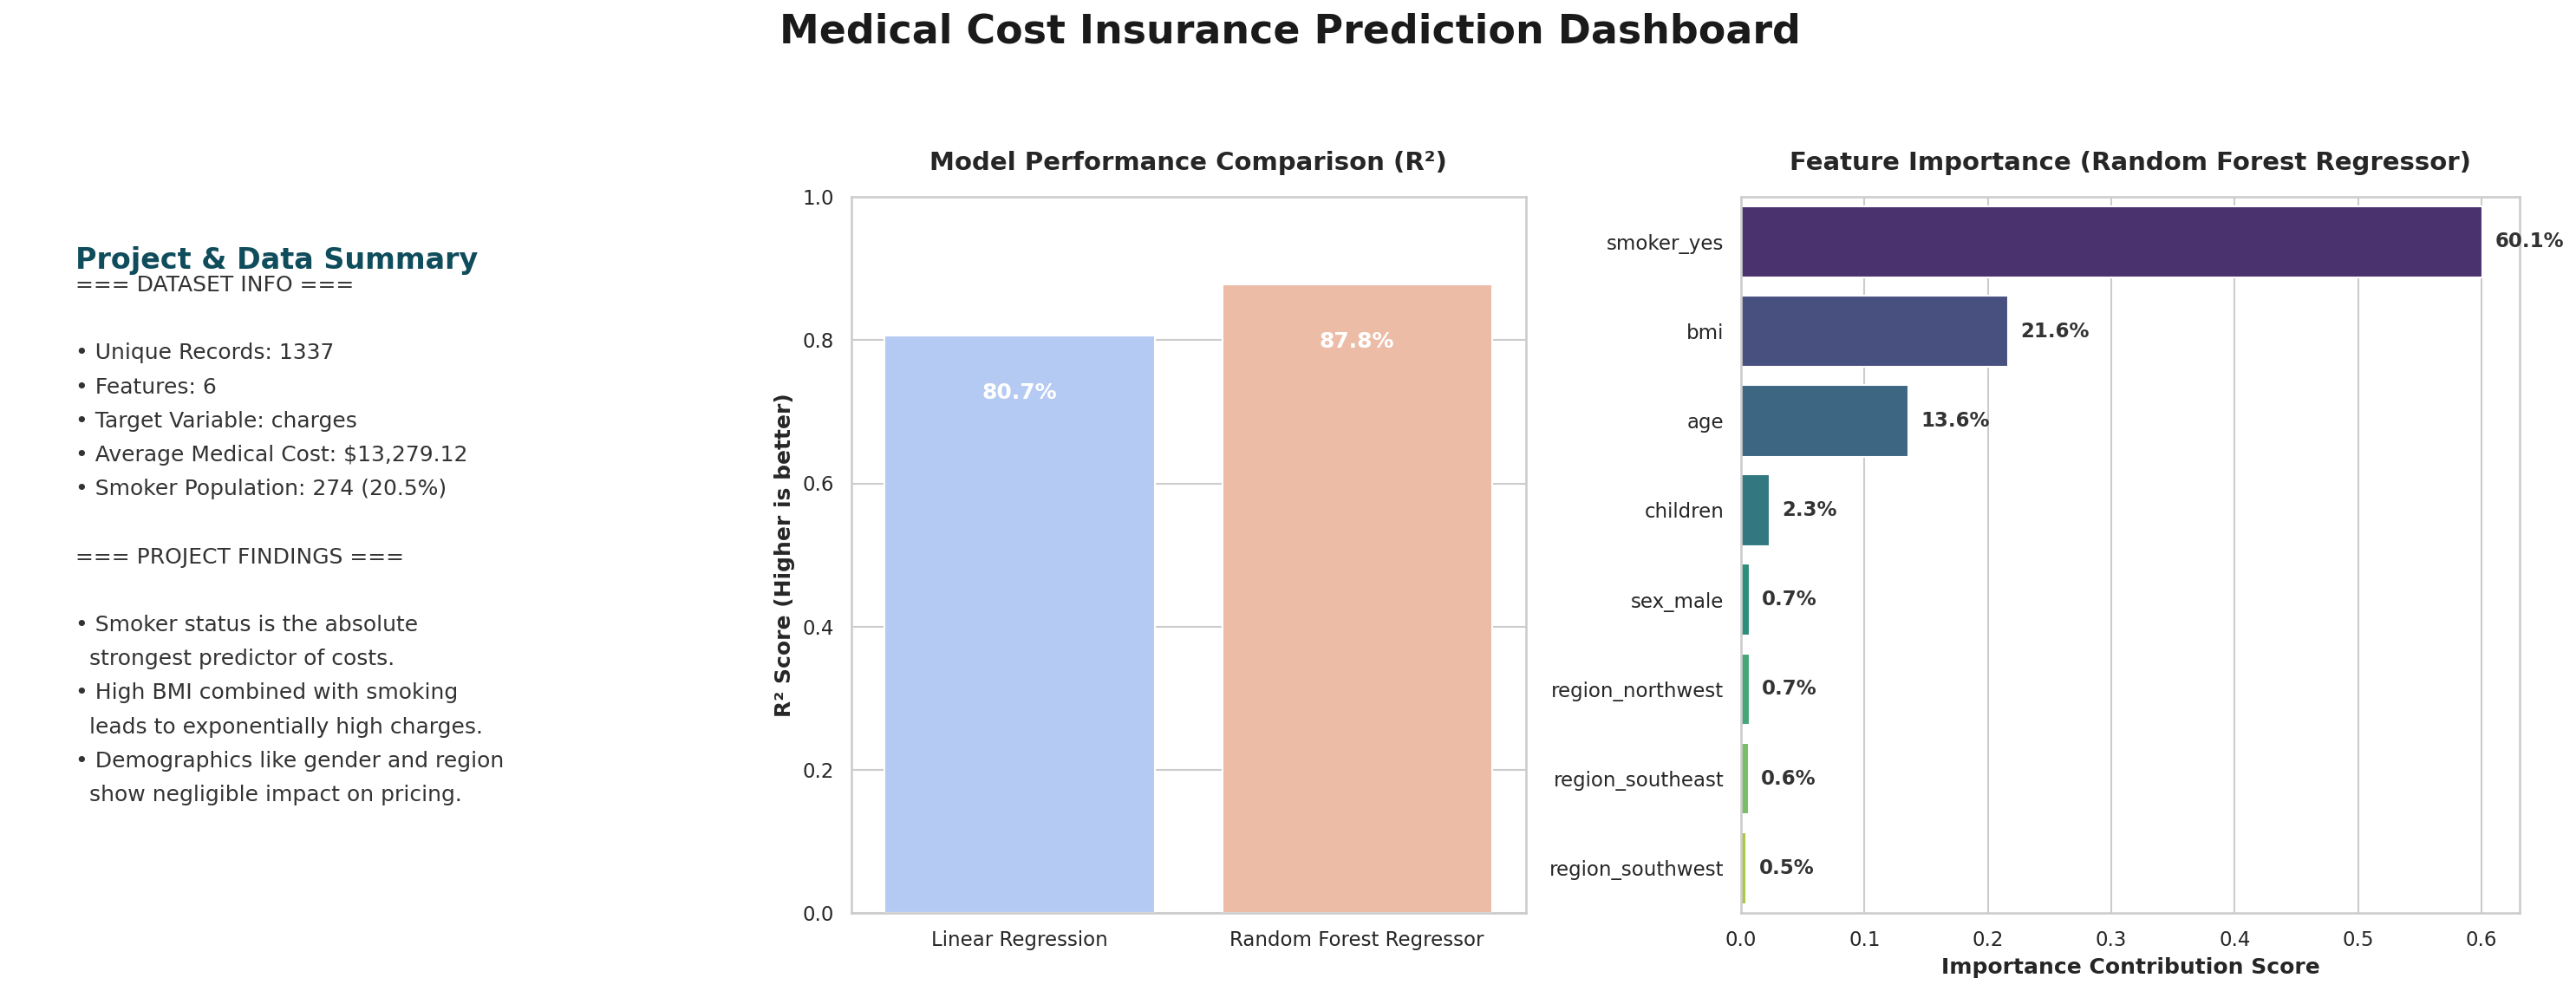

Dashboard successfully generated and saved to: project_dashboard.png


In [16]:
import matplotlib.gridspec as gridspec

# Set plotting styling
sns.set_theme(style="whitegrid")

# Create a wide, horizontal canvas (20 x 8 inches)
fig = plt.figure(figsize=(20, 8), dpi=150)
fig.suptitle('Medical Cost Insurance Prediction Dashboard', fontsize=22, fontweight='bold', color='#1a1a1a', y=0.98)

# Define Grid Layout: 1 Row, 3 Main horizontal columns
gs = gridspec.GridSpec(1, 3, width_ratios=[1.2, 1.3, 1.5], figure=fig)

# -----------------------------------------------------
# PANEL 1: Key Project Metrics & Text summary
# -----------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
ax1.axis('off')
ax1.patch.set_facecolor('#f7f9fa')

num_smokers = df[df['smoker'] == 'yes'].shape[0]
smoker_pct = (num_smokers / len(df)) * 100
avg_charge = df['charges'].mean()

summary_text = (
    "=== DATASET INFO ===\n\n"
    f"• Unique Records: {len(df)}\n"
    f"• Features: {df.shape[1] - 1}\n"
    f"• Target Variable: charges\n"
    f"• Average Medical Cost: ${avg_charge:,.2f}\n"
    f"• Smoker Population: {num_smokers} ({smoker_pct:.1f}%)\n\n"
    "=== PROJECT FINDINGS ===\n\n"
    "• Smoker status is the absolute\n"
    "  strongest predictor of costs.\n"
    "• High BMI combined with smoking\n"
    "  leads to exponentially high charges.\n"
    "• Demographics like gender and region\n"
    "  show negligible impact on pricing."
)

ax1.text(0.1, 0.9, "Project & Data Summary", fontsize=16, fontweight='bold', color='#0f4c5c')
ax1.text(0.1, 0.15, summary_text, fontsize=12, family='sans-serif', linespacing=1.8, color='#333333', verticalalignment='bottom')

# -----------------------------------------------------
# PANEL 2: Model Comparison Chart (Bar chart comparing R2 and MAE)
# -----------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

# Transform results for visualization
metrics_melted = results_df.reset_index().rename(columns={'index': 'Model'})

# Plot R2 score
sns.barplot(data=metrics_melted, x='Model', y='R2', ax=ax2, palette='coolwarm', hue='Model', legend=False)
ax2.set_ylim(0, 1.0)
ax2.set_ylabel('R² Score (Higher is better)', fontsize=12, fontweight='bold')
ax2.set_xlabel('')
ax2.set_title('Model Performance Comparison (R²)', fontsize=14, fontweight='bold', pad=15)

# Add exact value labels on top of bars
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2., p.get_height() - 0.08),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# -----------------------------------------------------
# PANEL 3: Feature Importance Plot
# -----------------------------------------------------
ax3 = fig.add_subplot(gs[0, 2])

sns.barplot(data=feature_importance_df, x='Importance', y='Feature', ax=ax3, palette='viridis', hue='Feature', legend=False)
ax3.set_title('Feature Importance (Random Forest Regressor)', fontsize=14, fontweight='bold', pad=15)
ax3.set_xlabel('Importance Contribution Score', fontsize=12, fontweight='bold')
ax3.set_ylabel('')

# Add percentage values to the bars
for i, p in enumerate(ax3.patches):
    width = p.get_width()
    ax3.text(width + 0.01, p.get_y() + p.get_height()/2, f"{width:.1%}",
             va='center', ha='left', fontsize=11, fontweight='bold', color='#333333')

plt.tight_layout(rect=[0, 0.03, 1, 0.93])

# Save the dashboard as a clean horizontal PNG
save_path = 'project_dashboard.png'
plt.savefig(save_path, bbox_inches='tight', dpi=200)
plt.show()

print(f"Dashboard successfully generated and saved to: {save_path}")